# How many donors does a perturbation map need? — learning curves on the atlas

Per repeat: 4 random **held-out test donors**, and the other 15 in a random order. Maps for every one of the 168
(stim, celltype) pairs are trained on the first k donors, k ∈ {1, 2, 3, 4, 5, 6, 8, 10, 12, 15}, and scored on the
test donors. There are 5 repeats. CellOT uses the paper's architecture and settings, trained many maps at once on
a GPU (`lc/train.py`; `lc/test_equivalence.py` proves this equals training them one by one). The closed-form maps
(`lc/baselines.py`) use the same training cells and test donors.

**Skill** per (map, test donor, quantile, marker) = 1 − |predicted − true| / |identity − true|. Only cases whose
true effect exceeds the atlas technical floor (0.0273) are kept; the curves show the median over cases, as a mean
± SD across repeats. **Ceiling** = the same skill for a split-half of the test donor's own stimulated cells: a rough
limit set by sampling noise (at half the cells, so it is pessimistic).

*Paper-style best* = the checkpoint with the lowest validation median error on held-out cells of the **training**
donors (the paper's selection rule, which never sees the test donors). *Last* = the final iterate (50k).

### How training and evaluation work

**One iteration = 11 optimizer steps**, as in the paper's CellOT loop:
1. Draw one target batch of 256 stimulated cells.
2. Do 10 steps of **g** (the transport map). Each uses a fresh batch of 256 unstimulated cells, and the loss is
   mean f(T(x)) − ⟨x, T(x)⟩, where T = ∇g. This loss contains **no target cells**: g sees the target only through f.
3. Do 1 step of **f** (the network that scores transported against real stimulated cells), with loss
   mean −f(T(x)) + f(y). It uses a fresh source batch and the target batch from step 1.

The optimizer is Adam (lr 1e-4, betas 0.5 / 0.9). The capped run does 50k iterations, i.e. 500k g-steps; the uncapped
run does 20k. Source and target batches are independent samples of the two distributions, not matched pairs.

**No epochs.** Every batch is drawn uniformly, with replacement, from the pooled training cells of the training donors
(a donor with more cells contributes more). With 11 source batches per iteration, each map draws ~140M source cells in
the capped run, so a cell is seen from ~20 times (Granulocytes at k = 15, uncapped) to ~10⁵ times (pDCs at k = 1).

**Three sets of cells:**
- *Training cells*: 80 % of each training donor's cells.
- *Validation cells*: the other 20 % (a fixed draw of 2,000). Every 2,500 iterations they give the median error
  that selects the "paper-style best" checkpoint.
- *Test donors*: 4 per repeat, never trained on. They are scored at every checkpoint, but only for plotting (the
  trajectory). No choice is ever made with them, so they cannot leak into training or checkpoint selection.

**Five repeats**, each with its own 4 test donors and its own random order of the other 15 donors. The k donors
are nested: the k = 5 donors are the k = 4 donors plus one.

**Ceiling (the dashed line).** A test donor's stimulated cells are split into two random halves, and one half's
quantiles are used as the "prediction" of the other's. The ceiling is 1 − |q(half A) − q(half B)| / effect, i.e. the
skill of a perfect map limited only by the finite number of cells. Each half has n/2 cells, which makes the ceiling
pessimistic (~√2 more noise), and plate-to-plate technical noise is ignored, which makes it optimistic. Read ~0.85–0.9.

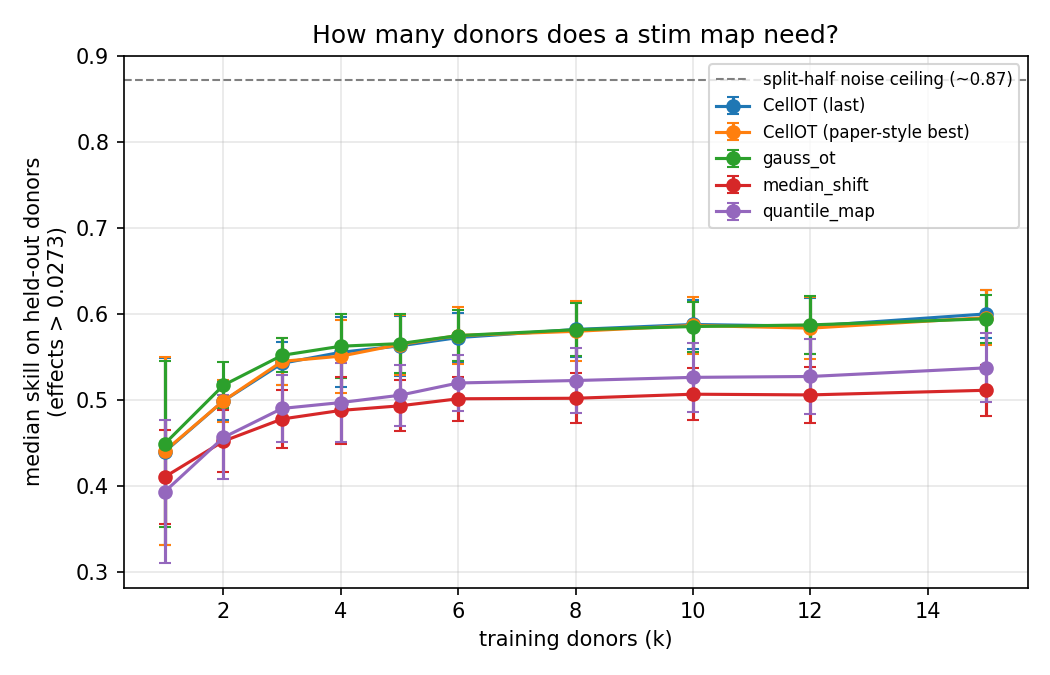

method,CellOT (last),CellOT (paper-style best),gauss_ot,identity,median_shift,quantile_map
k,,,,,,
1,0.440,0.441,0.450,0.0,0.411,0.394
2,0.499,0.499,0.518,0.0,0.452,0.457
3,0.543,0.545,0.552,0.0,0.478,0.491
4,0.556,0.551,0.563,0.0,0.488,0.497
5,0.563,0.565,0.566,0.0,0.494,0.506
6,0.573,0.575,0.575,0.0,0.502,0.520
8,0.582,0.580,0.582,0.0,0.502,0.523
10,0.588,0.587,0.586,0.0,0.507,0.527
12,0.586,0.584,0.588,0.0,0.506,0.528


In [1]:
import sys; sys.path.insert(0, "/scratch/users/bmerwan/atlas_heldout")   # the kernel starts in notebooks/
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from lc.paths import WORK
S = WORK / "summary"
pd.set_option("display.width", 200)
cur = pd.read_csv(S / "curve.csv")
display(Image(filename=str(S / "learning_curve.png")))
cur.pivot_table(index="k", columns="method", values="skill").round(3)

### Saturation: the first k reaching 90 % / 95 % of the 15-donor skill (per repeat)

In [2]:
pd.read_csv(S / "saturation_per_repeat.csv").pivot_table(index=["method", "fraction"], columns="repeat", values="k")

repeat                                0    1    2     3    4
method                    fraction                          
CellOT (last)             0.90      3.0  3.0  5.0   5.0  3.0
                          0.95      5.0  4.0  8.0  10.0  4.0
CellOT (paper-style best) 0.90      3.0  3.0  5.0   3.0  3.0
                          0.95      5.0  4.0  8.0   8.0  5.0
gauss_ot                  0.90      3.0  3.0  3.0   2.0  3.0
                          0.95      5.0  4.0  8.0   8.0  4.0
median_shift              0.90      3.0  1.0  5.0   2.0  3.0
                          0.95      5.0  3.0  5.0   2.0  4.0
quantile_map              0.90      3.0  3.0  5.0   2.0  4.0
                          0.95      5.0  4.0  8.0   2.0  5.0

### By stimulation

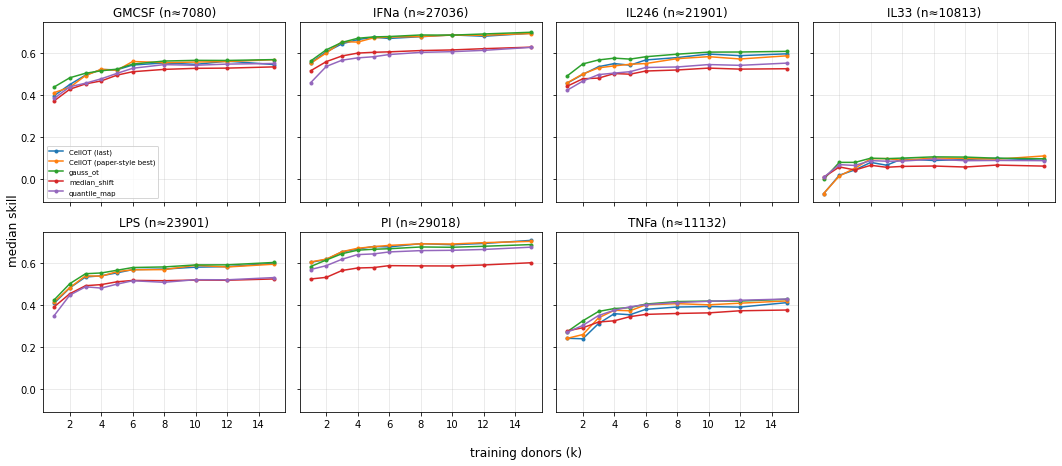

In [3]:
bs = pd.read_csv(S / "curve_by_stim.csv")
meths = [m for m in bs.method.unique() if m != "identity"]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True, sharey=True)
for ax, (st, g) in zip(axs.flat, bs.groupby("stim")):
    for m in meths:
        h = g[g.method == m]; ax.plot(h.k, h.median_skill, marker=".", label=m)
    ax.set_title(f"{st} (n≈{int(g.n.median())})"); ax.grid(alpha=.3)
axs.flat[0].legend(fontsize=7); axs.flat[-1].axis("off"); fig.supxlabel("training donors (k)"); fig.supylabel("median skill")
fig.tight_layout()

### By quantile (does the tail need more donors than the median?)

In [4]:
bq = pd.read_csv(S / "curve_by_q.csv")
bq[bq.method != "identity"].pivot_table(index="k", columns=["method", "q"], values="median_skill").round(2)

method CellOT (last)                         CellOT (paper-style best)                          ... median_shift                         quantile_map                        
q                 10    25    50    75    90                        10    25    50    75    90  ...           10    25    50    75    90           10    25    50    75    90
k                                                                                               ...                                                                          
1               0.37  0.44  0.49  0.48  0.44                      0.36  0.44  0.50  0.49  0.45  ...         0.26  0.39  0.50  0.46  0.38         0.14  0.24  0.42  0.51  0.47
2               0.43  0.49  0.53  0.53  0.49                      0.42  0.49  0.54  0.53  0.49  ...         0.26  0.39  0.55  0.51  0.43         0.22  0.32  0.48  0.55  0.52
3               0.49  0.54  0.57  0.57  0.53                      0.48  0.54  0.58  0.57  0.53  ...         0.29  0.42  0.58  0.54  0.44         0.27  0.37  0.52  0.58  0.54
4               0.50  0.56  0.59  0.58  0.54                      0.49  0.55  0.59  0.58  0.53  ...         0.29  0.42  0.59  0.56  0.46         0.29  0.39  0.52  0.58  0.55
5               0.50  0.56  0.60  0.59  0.55                      0.49  0.56  0.60  0.59  0.56  ...         0.30  0.44  0.60  0.56  0.46         0.28  0.39  0.53  0.60  0.57
6               0.50  0.56  0.60  0.60  0.57                      0.51  0.57  0.61  0.60  0.57  ...         0.32  0.46  0.61  0.56  0.45         0.30  0.40  0.55  0.61  0.58
8               0.52  0.58  0.61  0.61  0.57                      0.51  0.57  0.62  0.61  0.57  ...         0.31  0.46  0.61  0.56  0.45         0.30  0.41  0.54  0.61  0.58
10              0.52  0.59  0.61  0.61  0.58                      0.52  0.58  0.62  0.61  0.58  ...         0.31  0.46  0.62  0.57  0.46         0.31  0.41  0.55  0.62  0.58
12              0.53  0.58  0.61  0.61  0.58                      0.52  0.58  0.62  0.61  0.57  ...         0.32  0.45  0.61  0.57  0.46         0.32  0.42  0.55  0.62  0.58
15              0.54  0.60  0.63  0.63  0.59                      0.53  0.59  0.63  0.62  0.58  ...         0.32  0.47  0.62  0.57  0.46         0.33  0.43  0.56  0.63  0.59

[10 rows x 25 columns]

### Stricter cut: only effects > 0.1

In [5]:
s2 = pd.read_csv(S / "curve_per_repeat_effect_gt_0.1.csv")
s2.groupby(["method", "k"]).median_skill.mean().unstack(0).round(3)

method,CellOT (last),CellOT (paper-style best),gauss_ot,identity,median_shift,quantile_map
k,,,,,,
1,0.617,0.618,0.606,0.0,0.544,0.550
2,0.663,0.662,0.661,0.0,0.581,0.601
3,0.692,0.693,0.688,0.0,0.608,0.632
4,0.702,0.699,0.698,0.0,0.618,0.641
5,0.708,0.708,0.701,0.0,0.625,0.647
6,0.713,0.716,0.705,0.0,0.628,0.657
8,0.722,0.723,0.713,0.0,0.633,0.663
10,0.724,0.725,0.716,0.0,0.637,0.669
12,0.725,0.727,0.718,0.0,0.640,0.671


### CellOT: does it need all 50k iterations? (median skill vs training iteration, per k)

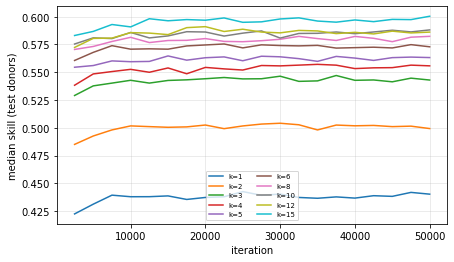

In [6]:
tr = pd.read_csv(S / "trajectory.csv")
fig, ax = plt.subplots(figsize=(7, 4))
for k, g in tr.groupby("k"):
    m = g.groupby("iteration")["median skill"].mean(); ax.plot(m.index, m.values, label=f"k={k}")
ax.set_xlabel("iteration"); ax.set_ylabel("median skill (test donors)"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3)

### Overfitting check (capped run)

For each map, the validation error late in training (iterations 42.5–50k) is compared with mid-training
(17.5–25k), split by how many training cells the map had. Memorising a small pool would show up as a rise.

In [7]:
from lc.paths import CACHE
rows = []
for r in range(5):
    d = WORK / f"train/repeat_{r}"; m = pd.read_csv(d / "maps.csv"); v = np.load(d / "val_err.npy")
    z = {ct: np.load(CACHE / f"{ct}.npz") for ct in m.celltype.unique()}
    n = [sum(int(round(len(z[row.celltype][f"Unstim|{dd}"]) * 0.8)) for dd in row.train.split()
             if f"Unstim|{dd}" in z[row.celltype].files) for row in m.itertuples()]
    rows.append(pd.DataFrame({"n_train_cells": n, "late_vs_mid_%": 100 * (v[16:20].mean(0) - v[6:10].mean(0)) / v[6:10].mean(0),
                              "jitter_%": 100 * np.abs(np.diff(v[10:], axis=0)).mean(0) / v[10:].mean(0)}))
OV = pd.concat(rows)
OV["pool"] = pd.cut(OV.n_train_cells, [0, 500, 2000, 10000, 50000, 1e9], labels=["<500", "500-2k", "2k-10k", "10k-50k", ">50k"])
display(OV.groupby("pool", observed=True).agg(maps=("pool", "size"), median_change_pct=("late_vs_mid_%", "median"),
        p10=("late_vs_mid_%", lambda x: x.quantile(.1)), p90=("late_vs_mid_%", lambda x: x.quantile(.9)),
        jitter_pct=("jitter_%", "median")).round(1))

,maps,median_change_pct,p10,p90,jitter_pct
pool,,,,,
<500,161,0.0,-11.4,14.8,10.0
500-2k,799,-0.6,-13.0,16.1,14.2
2k-10k,2619,0.2,-15.8,19.5,19.4
10k-50k,3664,-0.3,-18.6,22.3,23.1
>50k,1157,-2.0,-21.0,21.8,24.4


The median change is ~0 in every pool size, and symmetric within ±20 %, while the validation error jitters by ~20 %
between two consecutive evaluations. So there is **no systematic overfitting, even below 500 training cells**. The
ICNN is the gradient of a convex function, which it cannot bend around individual cells, and g only sees the target
through f. On the test donors the trajectory above never degrades either, and "last" and "paper-style best" coincide.

## Uncapped run: every cell, and a cells-per-donor axis

The capped run kept at most 10,000 cells per donor and condition, i.e. 29 % of all cells, and only ~4 % of
Granulocytes (median 240k per donor). The uncapped run (`cache_full/`, 2.7 GB) uses them all:
- the **donor curve** (k = 1…15, all cells);
- a **cells axis**: k ∈ {1, 2, 4, 15}, each trained on 1,000 / 5,000 / 20,000 cells per donor.

It runs 20k iterations: the capped trajectory shows the same skill at 20k and 50k, and the capped run is read at 20k
below for a like-for-like comparison. Test-donor quantiles come from ≤ 50k cells. Same 5 repeats and test donors.

,CellOT capped (20k it.),CellOT uncapped,gauss_ot capped,gauss_ot uncapped,quantile_map capped,quantile_map uncapped,median_shift capped,median_shift uncapped
k,,,,,,,,
1,0.44,0.44,0.45,0.45,0.39,0.40,0.41,0.41
2,0.50,0.50,0.52,0.51,0.46,0.45,0.45,0.45
3,0.54,0.54,0.55,0.55,0.49,0.49,0.48,0.47
4,0.55,0.55,0.56,0.56,0.50,0.49,0.49,0.48
5,0.56,0.56,0.57,0.56,0.51,0.50,0.49,0.49
6,0.57,0.57,0.58,0.57,0.52,0.52,0.50,0.50
8,0.58,0.58,0.58,0.58,0.52,0.52,0.50,0.50
10,0.59,0.59,0.59,0.58,0.53,0.53,0.51,0.51
12,0.59,0.58,0.59,0.59,0.53,0.53,0.51,0.50


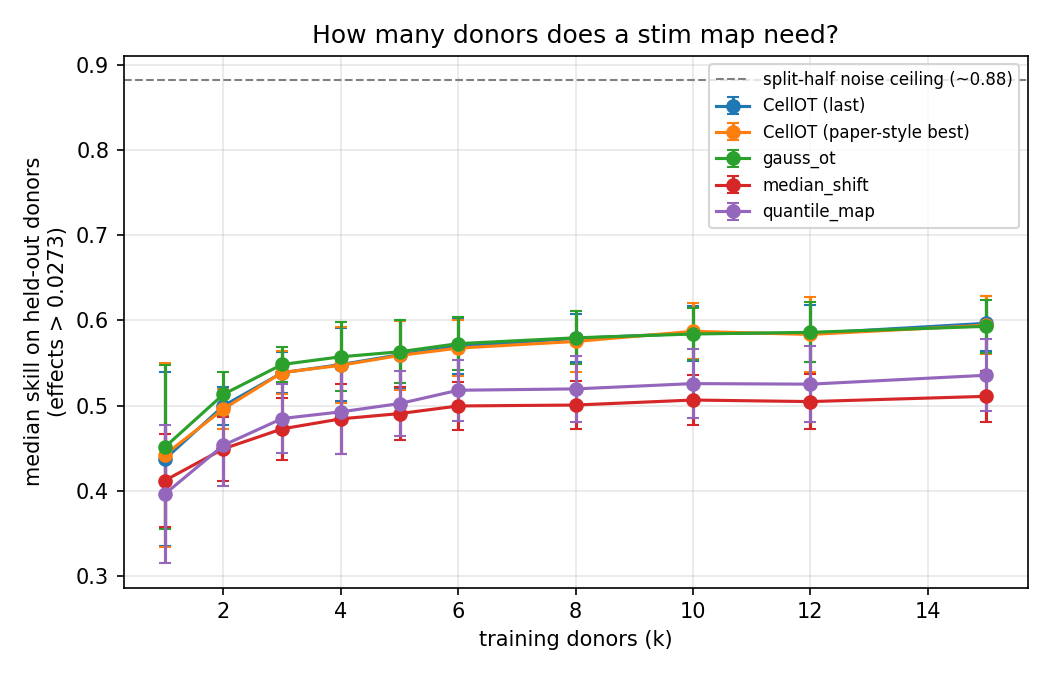

saturation (first k reaching 90 / 95 % of the k = 15 skill), uncapped, per repeat:


repeat                                0    1     2     3    4
method                    fraction                           
CellOT (last)             0.90      3.0  3.0   5.0   3.0  3.0
                          0.95      5.0  4.0  10.0   8.0  4.0
CellOT (paper-style best) 0.90      3.0  3.0   5.0   3.0  3.0
                          0.95      5.0  4.0   8.0  10.0  4.0
gauss_ot                  0.90      3.0  3.0   5.0   2.0  3.0
                          0.95      5.0  4.0   8.0   3.0  4.0
median_shift              0.90      3.0  1.0   5.0   2.0  3.0
                          0.95      5.0  3.0   5.0   2.0  5.0
quantile_map              0.90      3.0  3.0   5.0   2.0  4.0
                          0.95      5.0  4.0   8.0   2.0  5.0

In [8]:
SF = WORK / "summary_full"
cu = pd.read_csv(SF / "curve/curve.csv"); cc = pd.read_csv(S / "curve.csv"); trj = pd.read_csv(S / "trajectory.csv")
T = pd.DataFrame({"CellOT capped (20k it.)": trj[trj.iteration == 20000].groupby("k")["median skill"].mean(),
                  "CellOT uncapped": cu[cu.method == "CellOT (last)"].set_index("k").skill})
for m in ["gauss_ot", "quantile_map", "median_shift"]:
    T[f"{m} capped"] = cc[cc.method == m].set_index("k").skill; T[f"{m} uncapped"] = cu[cu.method == m].set_index("k").skill
display(T.round(2))
display(Image(filename=str(SF / "curve/learning_curve.png")))
print("saturation (first k reaching 90 / 95 % of the k = 15 skill), uncapped, per repeat:")
display(pd.read_csv(SF / "curve/saturation_per_repeat.csv").pivot_table(index=["method", "fraction"], columns="repeat", values="k"))

In [9]:
ce = pd.read_csv(SF / "cells/curve.csv")
full = cu[cu.k.isin([1, 2, 4, 15])].assign(cap=0)
allc = pd.concat([ce, full]); allc = allc[allc.method.isin(["CellOT (last)", "gauss_ot", "quantile_map"])]
display(allc.pivot_table(index=["method", "k"], columns="cap", values="skill").rename(columns={0: "all cells"}).round(2)
        .style.set_caption("Skill on held-out donors by training donors (k) and training cells per donor"))
g = pd.read_csv(SF / "curve/curve_by_celltype.csv")
display(g[(g.celltype == "Granulocytes") & g.method.isin(["CellOT (last)", "gauss_ot", "quantile_map"])]
        .pivot_table(index="k", columns="method", values="median_skill").round(2).style.set_caption("Granulocytes, uncapped"))

method,CellOT (last),gauss_ot,quantile_map
k,,,
1,0.510000,0.540000,0.550000
2,0.540000,0.560000,0.580000
3,0.610000,0.630000,0.620000
4,0.620000,0.630000,0.630000
5,0.620000,0.640000,0.640000
6,0.630000,0.650000,0.650000
8,0.630000,0.660000,0.660000
10,0.660000,0.680000,0.680000
12,0.660000,0.670000,0.670000


In [10]:
rows = []
for r in range(5):
    d = WORK / f"train_full/repeat_{r}/cells"; m = pd.read_csv(d / "maps.csv"); v = np.load(d / "val_err.npy")
    rows.append(pd.DataFrame({"cap": m["cap"], "k": m.k, "late_vs_mid_%": 100 * (v[6:8].mean(0) - v[2:4].mean(0)) / v[2:4].mean(0)}))
display(pd.concat(rows).groupby(["cap", "k"])["late_vs_mid_%"].median().unstack(0).round(1)
        .style.set_caption("Overfitting check on the cells axis: median % change of the validation error, late vs mid training"))

cap,1000,5000,20000
k,,,
1,-0.100000,-0.300000,-0.200000
2,-1.100000,0.000000,-1.600000
4,0.000000,-1.600000,-1.500000
15,-1.900000,-1.800000,-3.100000


### What "1k / 5k / 20k cells per donor" means, and when it actually removes cells

The cap is per **celltype, condition and donor**, on the training side (80 % of her cells). A (PI, CD4Tnaive) map
trained with "1,000 cells per donor" uses at most 1,000 unstimulated and 1,000 PI-stimulated CD4Tnaive cells from
each of its k donors. Many celltypes have fewer cells than the cap, so for them the cap changes nothing. The table
gives, per celltype, the training cells per donor and condition, and how often each cap binds.

In [11]:
from lc.paths import CELLTYPES
rows = []
for c in CELLTYPES:
    z = np.load(WORK / f"cache_full/{c}.npz"); n = np.array([len(z[k]) for k in z.files]) * 0.8
    rows.append({"celltype": c, "median": int(np.median(n)), "min": int(n.min()), "max": int(n.max()),
                 "1k binds": (n > 1000).mean(), "5k binds": (n > 5000).mean(), "20k binds": (n > 20000).mean()})
CT = pd.DataFrame(rows).sort_values("median", ascending=False).set_index("celltype")
display(CT.style.format({"1k binds": "{:.0%}", "5k binds": "{:.0%}", "20k binds": "{:.0%}"})
        .set_caption("Training cells per donor and condition (uncapped), and share of (condition, donor) blocks each cap reduces"))
big = CT[CT["median"] >= 8000].index.tolist()
g = pd.read_csv(SF / "cells/curve_by_celltype.csv"); f = pd.read_csv(SF / "curve/curve_by_celltype.csv")
g = pd.concat([g, f[f.k.isin([1, 2, 4, 15])].assign(cap=0)])
g = g[g.celltype.isin(big) & g.method.isin(["CellOT (last)", "gauss_ot"])]
display(g.groupby(["method", "k", "cap"]).median_skill.median().unstack("cap").rename(columns={0: "all"}).round(2)
        .style.set_caption(f"Cells axis on the large celltypes only ({', '.join(big)})"))

,median,min,max,1k binds,5k binds,20k binds
celltype,,,,,,
Granulocytes,191677,28951,363763,100%,100%,100%
CD4Tnaive,15667,3206,29839,100%,91%,18%
cMCs,10567,1156,26238,100%,91%,12%
CD8Tnaive,9316,2244,20390,100%,92%,1%
CD4Tcm,8489,2573,19588,100%,78%,0%
Bcells,7159,1838,19512,100%,76%,0%
CD56loCD16posNK,5882,1428,17748,100%,58%,0%
CD4Tem,4785,504,19751,98%,46%,0%
CD8Tem,4637,464,14432,95%,44%,0%


Only Granulocytes (median ~190k), CD4Tnaive (~16k), cMCs, CD8Tnaive and CD4Tcm (8–11k) have enough cells for all
three caps to bite. The 7 smallest celltypes (pDCs, mDCs, CD56hi NK, CD8Tcm CCR2+, ncMCs, intMCs, MDSCs; median
180–710) are mostly *below* 1,000, so for them the cells axis is empty. Restricted to the five large celltypes, the
picture is the same as overall: 1,000 cells from a single donor costs ~0.04, anything from 5k up is equal to "all",
and adding donors still matters far more (CellOT 0.56 at k = 1 → 0.67 at k = 15).

### Reading (2026-09-28)

- **Using every cell changes nothing.** The uncapped curves equal the capped ones to ±0.01 at every k, for every
  method. That includes Granulocytes, which went from 10k to up to 240k cells per donor (CellOT 0.51 → 0.66 from
  k = 1 to 15).
- **Donors matter, cells per donor barely do.**
  - With a single donor, 1,000 cells give 0.41 and anything ≥ 5,000 gives 0.44.
  - From k = 2 on, the number of cells per donor makes no difference.
  - Adding donors takes the skill from 0.44 (k = 1) to 0.54 (k = 3) and 0.60 (k = 15).
  - So one donor with many cells is **not** enough.
- **How many donors?** 90 % of the 15-donor skill is reached at k = 3 (2–5 depending on the repeat), 95 % at k = 4–10.
  The spread between repeats is large at k = 1 (±0.1): with one donor, it depends a lot on who that donor is.
- **The plateau (~0.6) sits well below the ceiling (~0.87).** What limits prediction for a new donor is how differently
  donors respond, which no population map captures. It is not the number of donors or cells.
- **CellOT = gauss_ot** at every k and every number of cells, on donors neither has seen. quantile_map and
  median_shift plateau ~0.06–0.08 lower.
- **No overfitting**, even at 1,000 cells from one donor: the validation error still drifts slightly down (−3 % to 0 %).

## What makes a donor useful? Three donor experiments (2026-09-29)

Code: designs `lc/design_donors.py`, analysis `lc/analyze_donors.py` → `work/lc/donors_summary/{hvpv,pairwise,small}/`.
Same skill as above (median over the (quantile, marker) cases above the 0.0273 floor, per map × test donor), CellOT at
20k iterations and the closed-form maps on identical training cells.

1. **HV vs PV** — per repeat (6), 2 HV + 3 PV test donors; from the remaining 6 HV / 8 PV, training sets of the same
   size k ∈ {2, 6} made of HV only, PV only, or half-half (MIX).
2. **Pairwise** — every donor alone as the training set, every other donor as test: a 19 × 19 matrix per method.
3. **Cells vs donors on the 8 smallest celltypes** (pDCs, mDCs, CD56hi NK, CD8Tcm CCR2+, ncMCs, intMCs, MDSCs,
   CD4Teff; ~180–920 training cells per donor): k ∈ {1, 2, 4, 7, 10, 15} × {25, 50, 100, 200, 400, all} cells per donor.

In [12]:
D = WORK / "donors_summary"
t = pd.read_csv(D / "hvpv/table.csv"); t = t[t.method.isin(["CellOT", "gauss_ot"])]
display(t.pivot_table(index=["method", "k"], columns="train_group", values=["HV", "PV"]).round(3)
        .style.set_caption("HV vs PV: median skill on HV test donors (left) and PV test donors (right), by training group"))
p = pd.read_csv(D / "hvpv/paired_tests.csv")
display(p[p.method.isin(["CellOT", "gauss_ot"])].round(4).style.hide(axis="index")
        .set_caption("Paired over (test donor, repeat): mean skill difference and Wilcoxon p"))

method,k,test_group,comparison,mean_diff,n_test_donor_repeats,p
CellOT,2,HV,HV - PV training,0.020500,12,0.203600
CellOT,2,HV,MIX - HV training,-0.004500,12,0.791000
CellOT,2,HV,MIX - PV training,0.016000,12,0.339400
CellOT,2,PV,HV - PV training,-0.055800,18,0.010400
CellOT,2,PV,MIX - HV training,0.012700,18,0.550900
CellOT,2,PV,MIX - PV training,-0.043100,18,0.003400
CellOT,6,HV,HV - PV training,0.037600,12,0.042500
CellOT,6,HV,MIX - HV training,-0.025000,12,0.052200
CellOT,6,HV,MIX - PV training,0.012600,12,0.266100
CellOT,6,PV,HV - PV training,-0.054600,18,0.000500


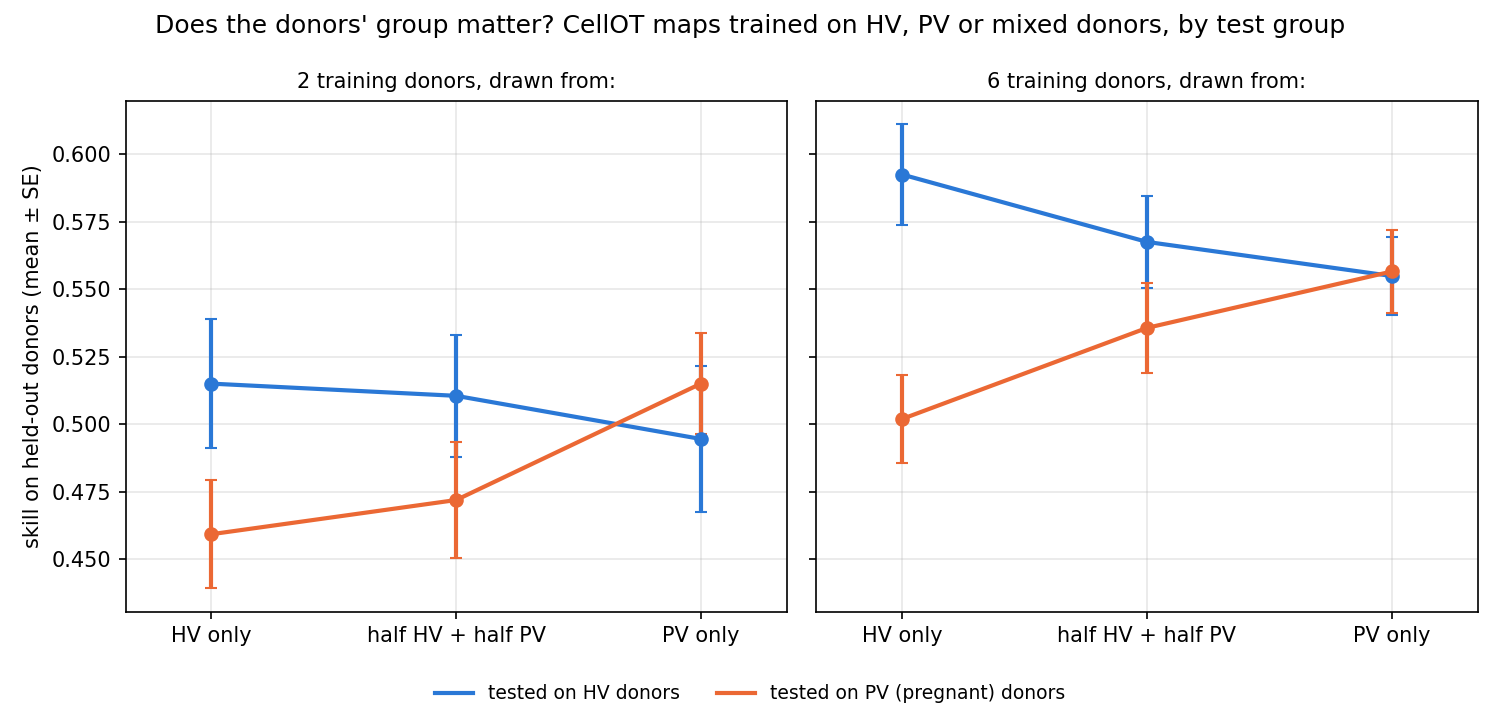

In [13]:
from IPython.display import Image
Image(str(D / "hvpv/hvpv.png"))

**How to read the table and the tests.** Each of the 6 repeats holds out 5 test donors (2 HV, 3 PV). From the other
6 HV / 8 PV, three training sets of the same size k are drawn (HV only, PV only, half-half), maps are trained on each
and all are scored on the same 5 test donors. The table is the mean skill per training set × test group. The paired
tests compare two training sets on the *same* test donor of the same repeat (12 HV pairs, 18 PV pairs).

**Why the differences look larger at k = 6 (they mostly are not).** On PV test donors the HV-vs-PV-training gap is the
same at both sizes (CellOT 0.056 at k = 2, 0.055 at k = 6); only the p-value shrinks. With 2 training donors the map
depends mostly on *who* those two are, a large random effect that hides the group effect. With 6, individual quirks
average out and what is left is the systematic HV/PV gap, a bias that adding donors of the wrong group does not reduce.
The gap that really grows is on HV test donors (0.020, n.s. → 0.038, p 0.04): adding HV donors helps HV donors a lot
(0.515 → 0.592), adding PV donors helps them less (0.495 → 0.555). Also, with 8 HV of which 2 are test, "6 HV" is
*all* remaining HV donors, so the HV6 sets of the 6 repeats nearly coincide, which lowers the variance at k = 6.

**HV vs PV.**
- **Pregnant donors are harder to predict, and only pregnant training donors fix it.** CellOT k = 6: HV-trained maps
  score 0.59 on HV but 0.50 on PV; PV-trained maps score 0.56 on PV *and* 0.56 on HV. On PV test donors, PV training
  beats HV training by 0.055 (p 5e-4), and MIX sits in between (+0.034 over HV, −0.021 under PV). gauss_ot and the
  diagonal maps show the same pattern, more strongly.
- Both directions cost something, PV more. At k = 6, on HV test donors HV training beats PV training by 0.038 (p 0.04);
  on PV test donors PV training beats HV training by 0.055 (p 5e-4). At k = 2 only the PV side is significant. A
  mixed set loses less on either side, so for a pregnancy application the atlas must contain pregnant donors.
- Limits: 6 repeats drawn from a pool of 8 HV / 11 PV, so the donors overlap between repeats and the p-values are
  optimistic.

### What differs between HV and PV donors, and is that what HV-trained maps get wrong?

`lc/hvpv_features.py` → `work/lc/donors_summary/hvpv_features/`. Two questions.

**A. Which features differ between the groups?** For every celltype × marker × quantile (q10–q90), three families:
*Unstim* (the baseline, which every map receives as input), *stim* (the stimulated level, what a map must output) and
*response* (stim − Unstim, the perturbation itself; the stim families are also × stim). Per feature, 8 HV vs 11 PV
donors: difference of means (arcsinh), Hedges' g, Mann–Whitney p with Benjamini–Hochberg q per family. With 8 vs 11
donors a sizeable |g| arises by chance, so the figure draws the chance distribution too.

**B. Where do HV-trained maps fail on PV donors?** In the HV/PV experiment (k = 6), for each PV test donor and each
case with a real effect: extra error = |pred(HV-only maps) − truth| − |pred(PV-only maps) − truth|, averaged per
feature over test donors and repeats, and related to that feature's HV–PV difference from part A.

donors,family,n features,median |g|,share |g| > 0.8,share q_BH < 0.1,median |PV - HV| (arcsinh)
all 19 donors,response,10920,0.440000,0.250000,0.055000,0.021000
all 19 donors,stim,10920,0.518000,0.332000,0.210000,0.121000
all 19 donors,unstim,1820,0.326000,0.230000,0.124000,0.064000
"without PV01, HV05",response,10920,0.478000,0.273000,0.047000,0.022000
"without PV01, HV05",stim,10920,0.749000,0.476000,0.296000,0.128000
"without PV01, HV05",unstim,1820,0.524000,0.374000,0.208000,0.069000


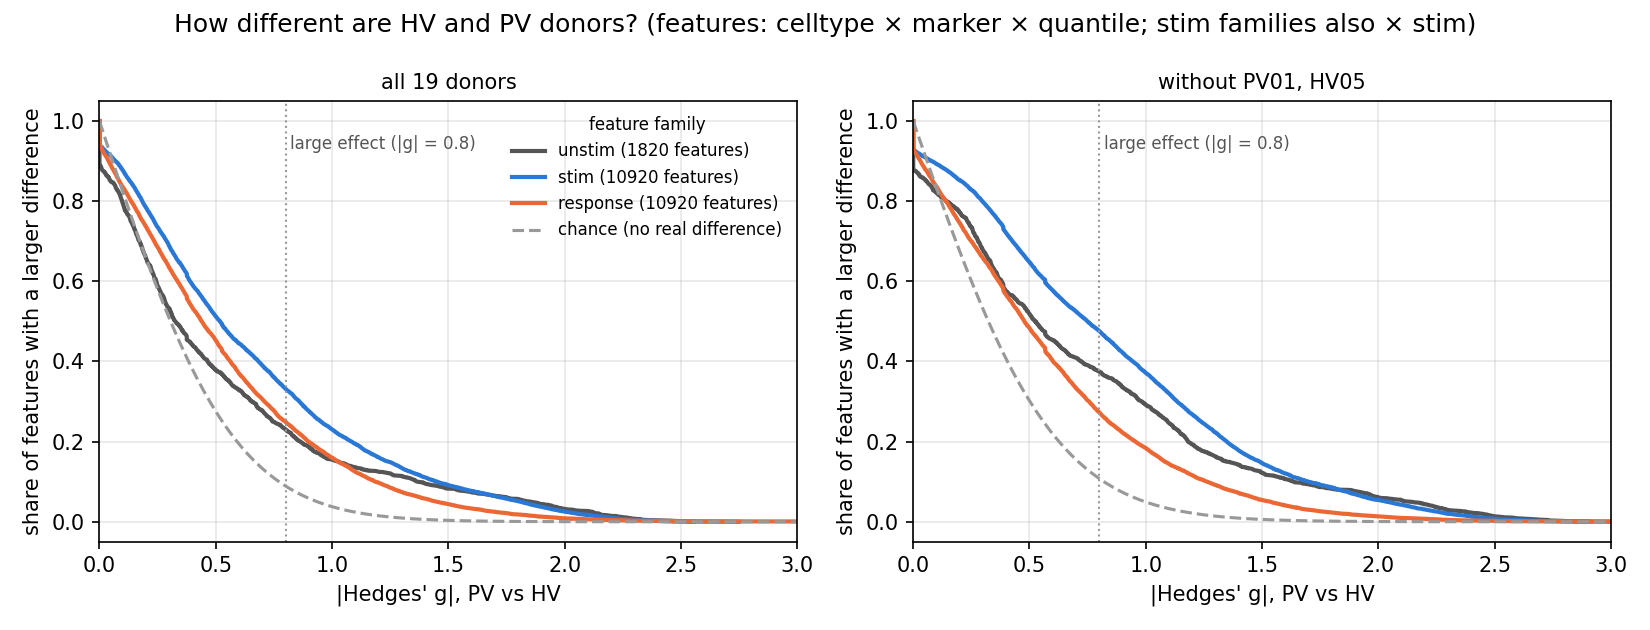

In [14]:
H = D / "hvpv_features"
display(pd.read_csv(H / "family_summary.csv").round(3).style.hide(axis="index")
        .set_caption("A. HV vs PV per feature family (chance level for |g| > 0.8: ~9 %)"))
Image(str(H / "group_diff_ecdf.png"))

In [15]:
display(pd.read_csv(H / "by_marker.csv", index_col=0).round(2).sort_values("unstim", ascending=False)
        .style.background_gradient(cmap="Blues", vmin=0, vmax=2).set_caption("Median |g| per marker and family"))
A = pd.read_csv(H / "group_diff.csv")
for fam in ["unstim", "response"]:
    top = pd.read_csv(H / f"top_{fam}.csv").head(8)
    display(top[["stim", "celltype", "marker", "q", "diff_PV_minus_HV", "hedges_g", "q_bh"]].round(3).style.hide(axis="index")
            .set_caption(f"Largest HV–PV differences, {fam}"))

,response,stim,unstim
marker,,,
pS6,0.520000,1.860000,1.950000
pMK2,0.290000,1.140000,1.010000
IkB,0.510000,0.690000,0.670000
pCREB,0.560000,0.860000,0.600000
HLADR,0.380000,0.590000,0.550000
pp38,0.480000,0.380000,0.250000
pNFkB,0.580000,0.310000,0.240000
pSTAT3,0.380000,0.370000,0.200000
CD25,0.290000,0.190000,0.190000


stim,celltype,marker,q,diff_PV_minus_HV,hedges_g,q_bh
Unstim,CD4negCD8negTcells,pS6,90,-0.365000,-2.553000,0.010000
Unstim,CD8Tem,pS6,90,-0.321000,-2.524000,0.010000
Unstim,ncMCs,pS6,10,-0.522000,-2.498000,0.010000
Unstim,CD4negCD8negTcells,pS6,75,-0.398000,-2.470000,0.010000
Unstim,CD8Tem,pS6,75,-0.351000,-2.458000,0.010000
Unstim,ncMCs,pS6,25,-0.476000,-2.416000,0.010000
Unstim,Granulocytes,pS6,90,-0.452000,-2.363000,0.010000
Unstim,CD4negCD8negTcells,pS6,50,-0.420000,-2.357000,0.010000


stim,celltype,marker,q,diff_PV_minus_HV,hedges_g,q_bh
LPS,MDSCs,pNFkB,10,0.371000,4.811000,0.011000
LPS,MDSCs,pS6,10,0.633000,3.666000,0.011000
IL246,Granulocytes,pSTAT3,75,0.502000,3.472000,0.011000
IL246,Granulocytes,pSTAT3,90,0.487000,3.431000,0.011000
IL246,Granulocytes,pSTAT5,90,0.326000,3.353000,0.011000
TNFa,MDSCs,pS6,10,0.379000,3.283000,0.011000
IL246,Granulocytes,pSTAT5,75,0.294000,3.193000,0.011000
IL246,Granulocytes,pSTAT3,50,0.479000,3.137000,0.011000


**A. What differs.**
- **The baseline differs mostly in a few markers, and all in the same direction.** PV donors have **lower pS6 at
  baseline in every celltype** (median g −1.9, −0.34 arcsinh; significant in 96 % of pS6 features), and lower pMK2
  and IkB (g −1.0 / −0.7). The other Unstim markers barely differ, and pSTAT1/6 are at zero in both groups.
- **The stimulated level differs the most** (33 % of features with |g| > 0.8, 21 % FDR-significant). It mostly carries
  the baseline difference: the pS6 difference persists after every stimulation.
- **The response differs less often** (25 % with |g| > 0.8 against 9 % by chance, but only 5.5 % FDR-significant), and
  in arcsinh the gap is small (median 0.02 against 0.06 for the baseline). Where it is significant, **PV donors
  mostly respond less** (86 % of the significant response differences are PV < HV), mainly pS6, pCREB, pNFkB, pSTAT6
  and pSTAT5, under PI, IFNa and IL-2/4/6. The largest single differences go the other way: myeloid cells respond
  *more* in PV (MDSCs under LPS, pNFkB g +4.8 and pS6 +3.7; Granulocytes under IL-2/4/6, pSTAT3/5 g +3.2–3.5).
- Without the two baseline outliers (PV01, HV05), the baseline and stimulated-level differences grow (median |g| 0.33
  → 0.52 and 0.52 → 0.75); the response differences hardly change. So the outliers were hiding group differences,
  not creating them.
- Caveat: HV and PV donors are two cohorts, so part of these differences (a uniform pS6 offset in particular) could
  be technical (acquisition batch) rather than pregnancy. This data cannot separate the two.

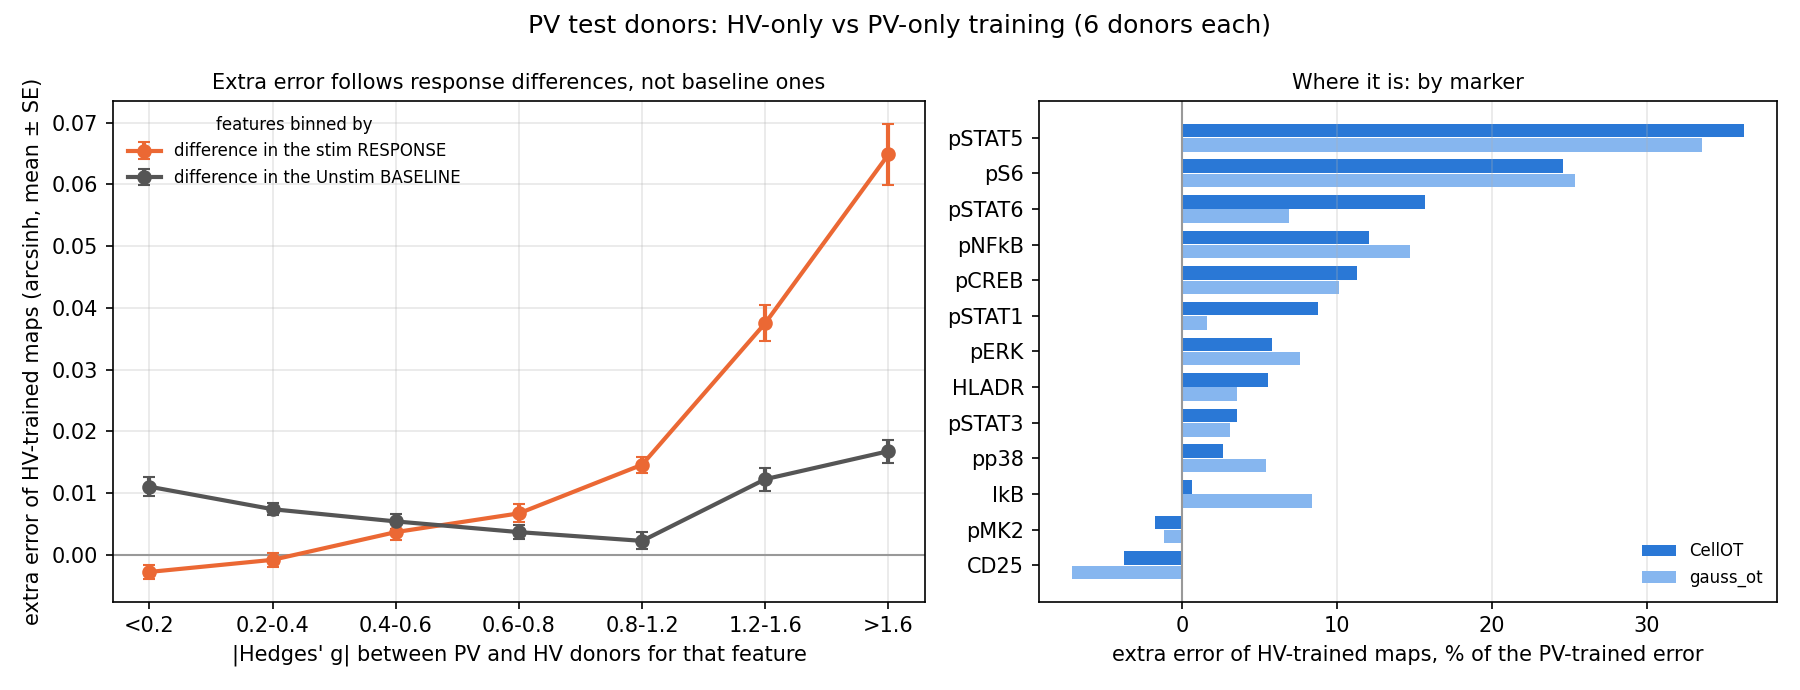

In [16]:
display(pd.read_csv(H / "excess_summary.csv").set_index(["method", "test donors"]).T.round(3)
        .style.set_caption("B. Extra error of HV-trained vs PV-trained maps (k = 6), per test group"))
Image(str(H / "excess_vs_groupdiff.png"))

In [17]:
F = pd.read_csv(H / "excess_by_feature.csv"); rows = []
for m in ["CellOT", "gauss_ot"]:
    f = F[(F.method == m) & (F.test_group == "PV")]; b = f.g_response.abs() > 0.8
    rows.append({"method": m, "features with a large response difference (|g| > 0.8)": b.mean(),
                 "share of the net extra error they carry": f.excess[b].sum() / f.excess.sum(),
                 "HV-trained worse, those features": (f.excess[b] > 0).mean(),
                 "HV-trained worse, all other features": (f.excess[~b] > 0).mean()})
display(pd.DataFrame(rows).set_index("method").round(2).style.set_caption("Is everything shifted, or a few features?"))
for by in ["stim", "celltype"]:
    t = pd.read_csv(H / f"excess_PVtest_by_{by}.csv"); t = t[t.method == "CellOT"].sort_values("excess", ascending=False)
    display(t.assign(rel=t.excess / t.err_PV).head(8).round(3).style.hide(axis="index")
            .set_caption(f"CellOT, PV test donors: extra error by {by} (rel = extra / PV-trained error)"))

,features with a large response difference (|g| > 0.8),share of the net extra error they carry,"HV-trained worse, those features","HV-trained worse, all other features"
method,,,,
CellOT,0.280000,0.910000,0.660000,0.470000
gauss_ot,0.280000,0.990000,0.650000,0.450000


method,stim,excess,share_worse,err_PV,rel
CellOT,PI,0.018000,0.525000,0.137000,0.128000
CellOT,IL246,0.010000,0.495000,0.097000,0.107000
CellOT,LPS,0.009000,0.551000,0.097000,0.094000
CellOT,TNFa,0.009000,0.583000,0.071000,0.127000
CellOT,IFNa,0.004000,0.491000,0.080000,0.053000
CellOT,GMCSF,0.004000,0.575000,0.087000,0.045000
CellOT,IL33,-0.000000,0.476000,0.068000,-0.005000


method,celltype,excess,share_worse,err_PV,rel
CellOT,MDSCs,0.029000,0.601000,0.108000,0.266000
CellOT,intMCs,0.022000,0.602000,0.104000,0.214000
CellOT,Granulocytes,0.020000,0.627000,0.077000,0.262000
CellOT,mDCs,0.016000,0.590000,0.136000,0.121000
CellOT,Bcells,0.011000,0.491000,0.091000,0.122000
CellOT,pDCs,0.011000,0.539000,0.115000,0.096000
CellOT,CD4Tem,0.010000,0.482000,0.082000,0.121000
CellOT,CD8Tcm_CCR2pos,0.010000,0.527000,0.110000,0.090000


**B. What HV-trained maps get wrong on PV donors.**
- **Not everything is shifted.** Over all features, HV-trained maps are worse on only 52 % of them (a coin flip), and
  the average extra error is +0.008 arcsinh (+9 % of the PV-trained error).
- **The loss sits where PV donors *respond* differently.** The 28 % of features with a large response difference
  (|g| > 0.8) carry **91 %** of the net extra error for CellOT (99 % for gauss_ot); HV-trained maps are worse on 66 %
  of them, against 47 % of all other features. The extra error rises steeply with the response difference (left
  panel: ~0 below |g| 0.4, 0.065 above 1.6).
- **The baseline difference costs nothing** (ρ −0.02 between extra error and |g Unstim|). pS6 is the largest baseline
  difference, and its extra error comes from its response differences, not from its baseline. This is expected: the
  maps take each donor's own Unstim cells as input, so a different baseline is handled. What a map cannot know from
  HV donors is that PV donors respond differently.
- **By marker**: pSTAT5 (+36 % of the PV-trained error), pS6 (+25 %), pSTAT6 (+16 %), then pNFkB and pCREB (+11–12 %).
  CD25 and pMK2 are not worse. **By celltype**: myeloid first (MDSCs +27 %, Granulocytes +26 %, intMCs +21 %, mDCs
  +12 %). **By stim**: PI, IL-2/4/6, LPS and TNFa (+9–13 %); IL33 0.
- CellOT and gauss_ot lose in the same places and by similar amounts, so this is a property of the training donors,
  not of the model.
- The mirror case costs about as much per feature: on HV donors, PV-trained maps are worse than HV-trained ones by
  0.009 arcsinh on average, in 60 % of features. In skill the PV side loses more (0.055 against 0.038 at k = 6).

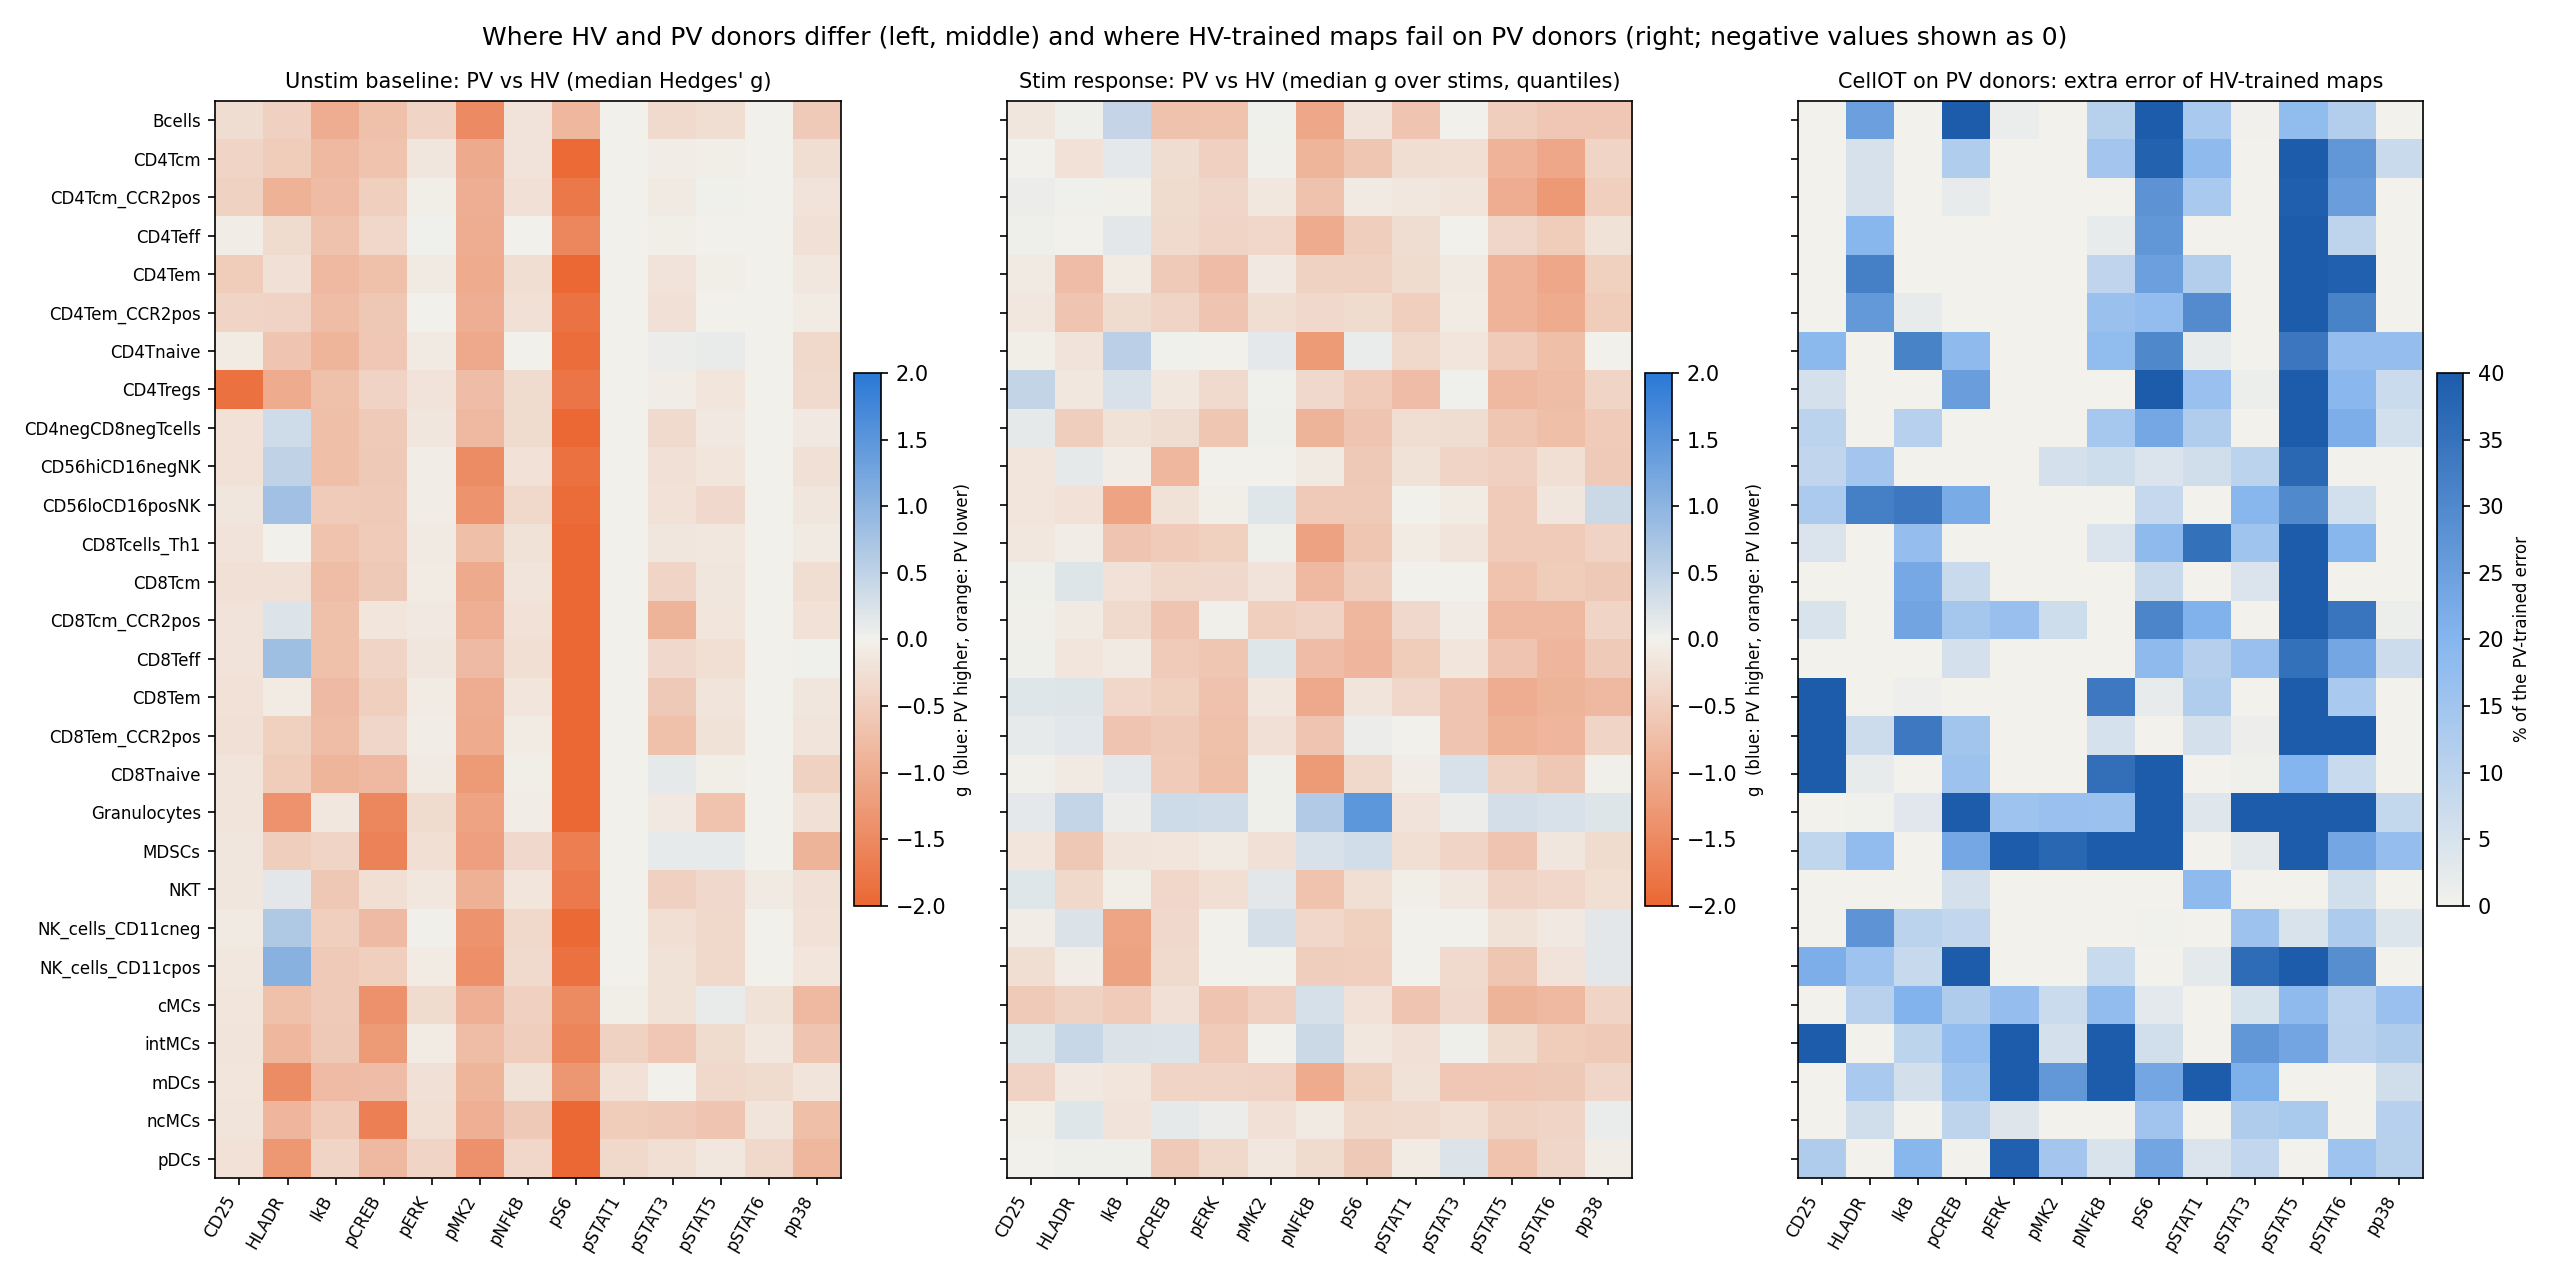

In [18]:
Image(str(H / "where_heatmaps.png"))

**Side by side, by celltype × marker.** Left: the baseline gap is one column, pS6 lower in PV everywhere (plus pMK2,
IkB, and pCREB in myeloid cells). Middle: the response gap is weak and diffuse, mostly PV responding a little less
(pNFkB in lymphocytes, pSTAT5/6 in T cells), with Granulocytes pS6 and MDSCs as the places PV respond more. Right:
the extra error does **not** follow the left map. The pS6 baseline gap is uniform across celltypes, but its extra
error is patchy (large in B cells, CD4Tcm, CD4Tregs, CD8Tnaive, Granulocytes, MDSCs; small elsewhere), so it tracks
pS6 *response* differences, not the baseline. The largest cost is pSTAT5 in almost every T-cell subset (where PV
respond less), then pCREB / pERK / pNFkB in myeloid cells, where PV respond differently. The medians over stims in the middle panel dilute stim-specific differences, which is
why the right panel is sharper than the middle one; the binned plot above is the per-feature version.

,CellOT,gauss_ot,median_shift,quantile_map
variance share: train donor,0.204000,0.162000,0.202000,0.118000
variance share: test donor,0.413000,0.367000,0.342000,0.380000
variance share: interaction (the pair),0.357000,0.458000,0.445000,0.498000
"rho(skill, response distance)",-0.544000,-0.613000,-0.568000,-0.568000
"rho(skill, baseline distance)",-0.828000,-0.661000,-0.312000,-0.476000
"rho(pair residual, response distance)",-0.522000,-0.538000,-0.506000,-0.535000
mean skill same group,0.420000,0.471000,0.442000,0.420000
mean skill other group,0.383000,0.437000,0.412000,0.373000
"rho(train goodness, response_atypicality)",-0.716000,-0.775000,-0.775000,-0.816000
"rho(test ease, response_atypicality)",-0.363000,-0.444000,-0.463000,-0.381000


,as training donor,as test donor,group,response_size,response_atypicality,baseline_atypicality,median_cells
PV01,0.217000,0.109000,PV,1.425000,0.396000,2.275000,1851.500000
HV05,0.273000,0.260000,HV,1.485000,0.310000,2.186000,2552.500000
PV09,0.396000,0.327000,PV,1.085000,0.460000,1.093000,2617.000000
PV10,0.416000,0.361000,PV,1.169000,0.416000,1.202000,3956.500000
PV11,0.390000,0.364000,PV,1.309000,0.390000,0.885000,2431.000000
PV02,0.419000,0.382000,PV,1.468000,0.370000,0.770000,2433.000000
PV03,0.429000,0.391000,PV,1.317000,0.312000,0.849000,2203.000000
PV07,0.404000,0.401000,PV,1.393000,0.383000,0.798000,3958.500000
HV08,0.360000,0.411000,HV,1.638000,0.512000,1.169000,5746.000000
HV09,0.455000,0.429000,HV,1.405000,0.338000,0.644000,5502.000000


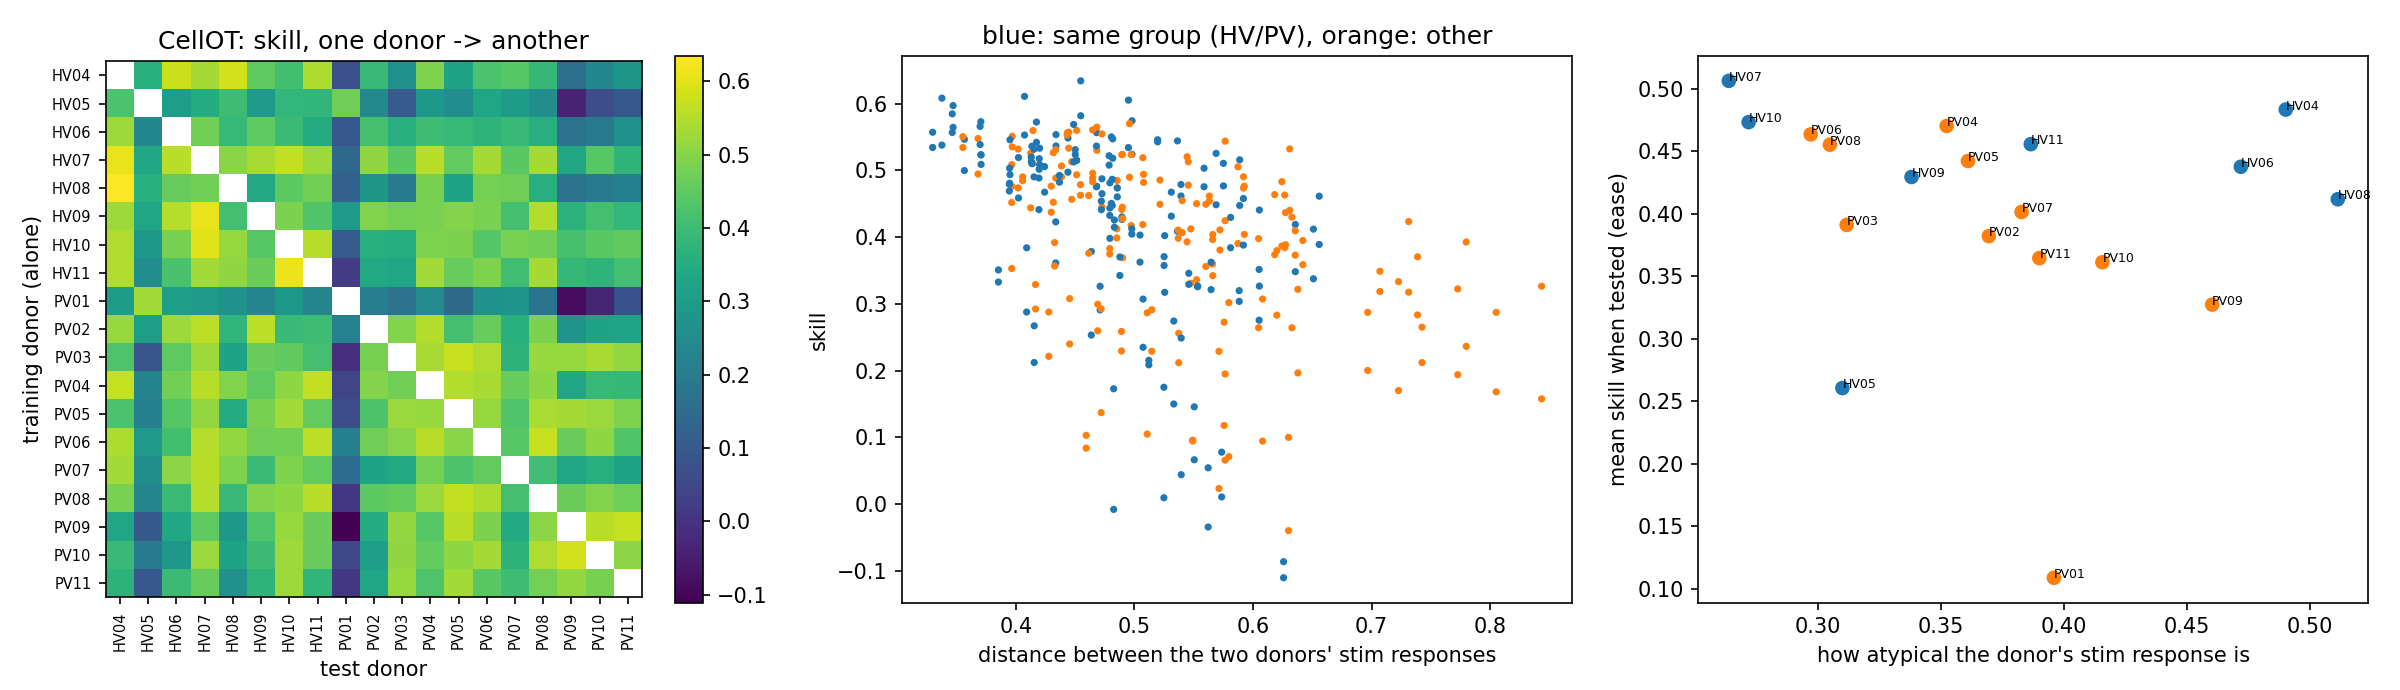

In [19]:
display(pd.read_csv(D / "pairwise/summary.csv", index_col=0).round(3)
        .style.set_caption("Pairwise (one training donor → one test donor): variance decomposition and Spearman correlations"))
sc = pd.read_csv(D / "pairwise/donor_scores_CellOT.csv", index_col=0)
display(sc.sort_values("as test donor").round(3).style.set_caption(
    "CellOT, per donor: mean skill as the training donor and as the test donor, and her descriptors"))
Image(str(D / "pairwise/pairwise_CellOT.png"))

**How to read the pairwise figure.** Left: the 19 × 19 matrix, row = the single training donor, column = the test
donor, value = median over the ~168 (stim, celltype) maps of the per-map skill. Middle: one point per ordered pair
(A trains, B is tested; 342 points; A→B and B→A are two points). y = that skill; x = the distance between A's and B's
stim responses: for each (stim, celltype) the Euclidean distance between their 13-marker response vectors (median
stim − median Unstim), averaged over pairs. Blue = same group, orange = HV↔PV. Right: per donor, mean skill when
tested vs how atypical her response is.

**Why most ρ are negative.** They are Spearman correlations between a skill (higher = better) and a distance or an
atypicality (higher = more different), so negative means "the more different, the worse". *Train goodness* = a
donor's mean skill as the training donor, over all test donors; *test ease* = her mean skill as the test donor, over
all training donors. The positive ones are cells (+0.47) and response size (+0.34) for test ease: more cells give a
less noisy truth, and a larger response is easier to recover proportionally.

**Pairwise: what makes a good training donor and an easy test donor.** Descriptors, per donor, averaged over
celltypes/pairs: *response size* = norm of her 13-marker median stim − Unstim shift; *response atypicality* = distance
of her shift from the mean shift of the other donors; *baseline atypicality* = the same for her Unstim medians.
- **Who is tested matters most**: 41 % of the variance of CellOT's skill is the test donor, 20 % the training donor,
  36 % the specific pair.
- **Skill falls with how different the two donors are.** With the distance between their stim responses (ρ −0.54) —
  and for CellOT even more with the distance between their *baselines* (ρ −0.83, against −0.31 for median_shift). This
  is the price of an input-dependent map: CellOT reads the Unstim cells, so a training donor whose baseline differs
  from the test donor's moves her cells in the wrong place. A constant shift does not care.
- **A good training donor is a typical one** — typical response (ρ −0.72) and typical baseline (ρ −0.83). A large
  response does not help. **An easy test donor** has a typical baseline (ρ −0.72), more cells (ρ +0.47) and a larger
  response (ρ +0.34; a larger effect is easier to recover proportionally).
- **Same group helps a little**: 0.42 same (HV→HV or PV→PV) vs 0.38 across.
- **Two outlier donors, PV01 and HV05**, are the worst both as training donors (0.22, 0.27) and as test donors (0.11,
  0.26), and have by far the most atypical baselines (2.27 and 2.19 against ≤ 1.2 for everyone else). That looks like
  a sample-level difference, worth a QC look at their Unstim files (the same kind of check as OOL's 36_G1 / 52_G1).

method,doubling the donors (same cells per donor),doubling the cells per donor (same donors),n
CellOT,0.295000,0.185000,36720
gauss_ot,0.142000,0.081000,36720
median_shift,0.067000,0.038000,36720
quantile_map,0.095000,0.058000,36720


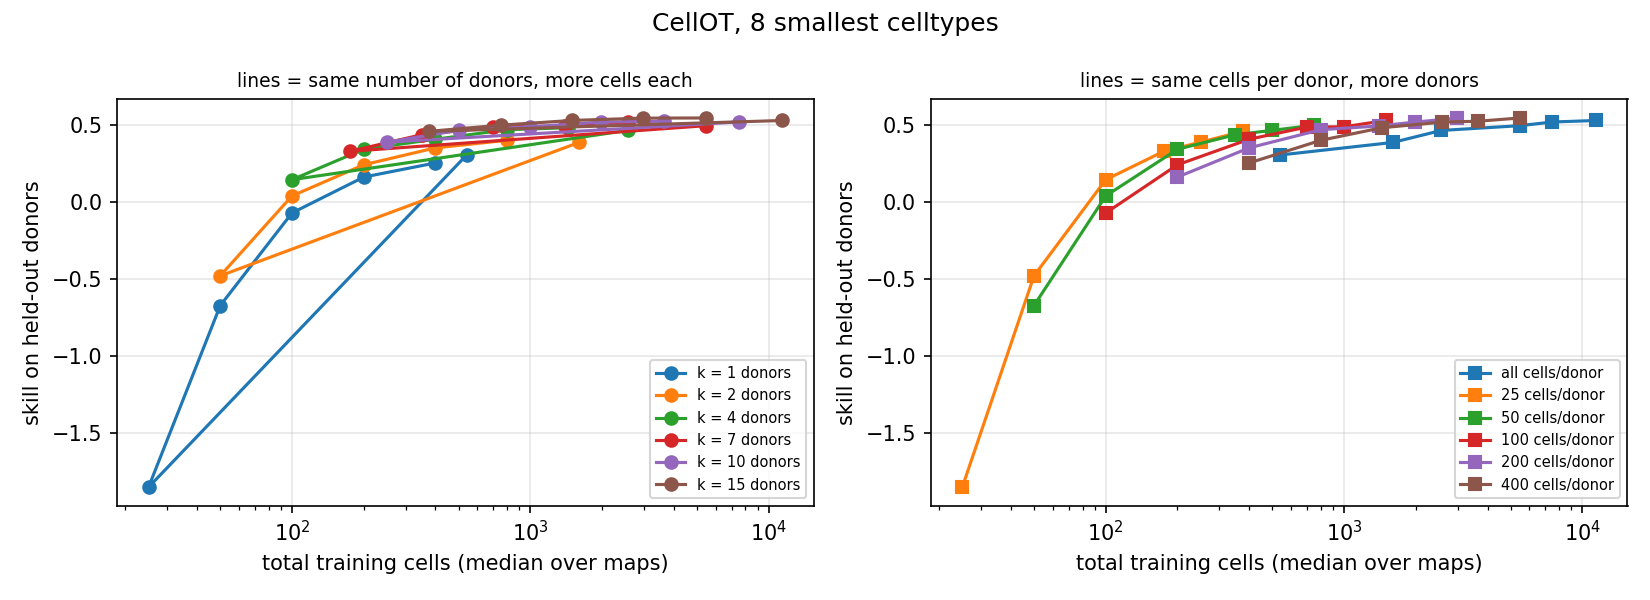

In [20]:
display(pd.read_csv(D / "small/doubling_effects.csv").round(3).style.hide(axis="index")
        .set_caption("8 smallest celltypes: mean skill gain from doubling the donors vs doubling the cells per donor"))
g = pd.read_csv(D / "small/grid.csv")
display(g.pivot_table(index=["method", "k"], columns="cap", values="skill").rename(columns={0: "all"}).round(2)
        .style.set_caption("Median skill by training donors (rows) and cells per donor (columns; 'all' ≈ 180–920)"))
Image(str(D / "small/small_CellOT.png"))

**Cells vs donors where cells are scarce.**
- **Doubling the donors is worth ~1.6× doubling the cells** (CellOT +0.29 vs +0.19; gauss_ot +0.14 vs +0.08).
- **At a fixed budget of training cells, more donors with fewer cells wins** (right panel: the "all cells/donor" line,
  i.e. few donors with many cells, lies below the others at the same total). E.g. ~1,500 training cells: 2 donors × all
  their cells 0.39, 4 × 400 0.48, 7 × 200 0.49, 15 × 100 0.53.
- **CellOT needs a minimum number of cells, gauss_ot much less.** With one donor and 25 cells CellOT is at −1.85
  (much worse than predicting no effect), gauss_ot −0.63. From ~100 cells per donor and ≥ 4 donors both reach the
  ~0.5 plateau, and at 15 donors they are equal (0.53).
- At k = 15, "all cells" (0.53) is not above 400 cells (0.55): the differences between caps at this end are noise.

### pDCs and mDCs: same number of cells, split between more or fewer donors (2026-09-30)

`lc/small_budget.py` → `work/lc/donors_summary/small_budget/`, read from the small-celltype runs above (no new
training). No pDC donor has 1,000 cells (the largest has ~440 Unstim training cells, the median ~200; mDCs up to ~690,
median ~290). The 931 in the per-celltype table above is a single *stimulated* block (donor HV11 under PI); a map
needs Unstim cells as its source, and budgets here count those. So the budgets are 100 to 1,500 training cells in total, each split as k donors × (budget / k) cells.
A point is kept when the actual number of training cells is within 30 % of the budget (a donor with fewer cells than
the cap gives all she has). Skill = median over (map, test donor) per repeat, mean ± SD over the 5 repeats.

k,1,2,4,7,15
budget,,,,,
100,0.02 ± 0.24 (1×100),0.10 ± 0.15 (2×50),0.19 ± 0.16 (4×25),,
200,0.14 ± 0.18 (1×200),0.29 ± 0.14 (2×100),0.31 ± 0.13 (4×50),0.33 ± 0.11 (7×25),
400,0.24 ± 0.11 (1×400),0.27 ± 0.11 (2×200),0.40 ± 0.07 (4×100),0.43 ± 0.09 (7×50),0.44 ± 0.07 (15×25)
750,,,0.42 ± 0.07 (4×200),0.43 ± 0.06 (7×100),0.48 ± 0.06 (15×50)
1500,,,,0.46 ± 0.12 (7×200),0.50 ± 0.07 (15×100)


k,1,2,4,7,15
budget,,,,,
100,-0.09 ± 0.12 (1×100),-0.07 ± 0.17 (2×50),0.05 ± 0.13 (4×25),,
200,0.06 ± 0.23 (1×200),0.11 ± 0.07 (2×100),0.28 ± 0.06 (4×50),0.23 ± 0.12 (7×25),
400,0.14 ± 0.28 (1×400),0.27 ± 0.08 (2×200),0.35 ± 0.07 (4×100),0.38 ± 0.10 (7×50),0.31 ± 0.09 (15×25)
750,,0.28 ± 0.13 (2×400),0.39 ± 0.07 (4×200),0.40 ± 0.07 (7×100),0.38 ± 0.06 (15×50)
1500,,,0.38 ± 0.09 (4×400),0.43 ± 0.03 (7×200),0.45 ± 0.06 (15×100)


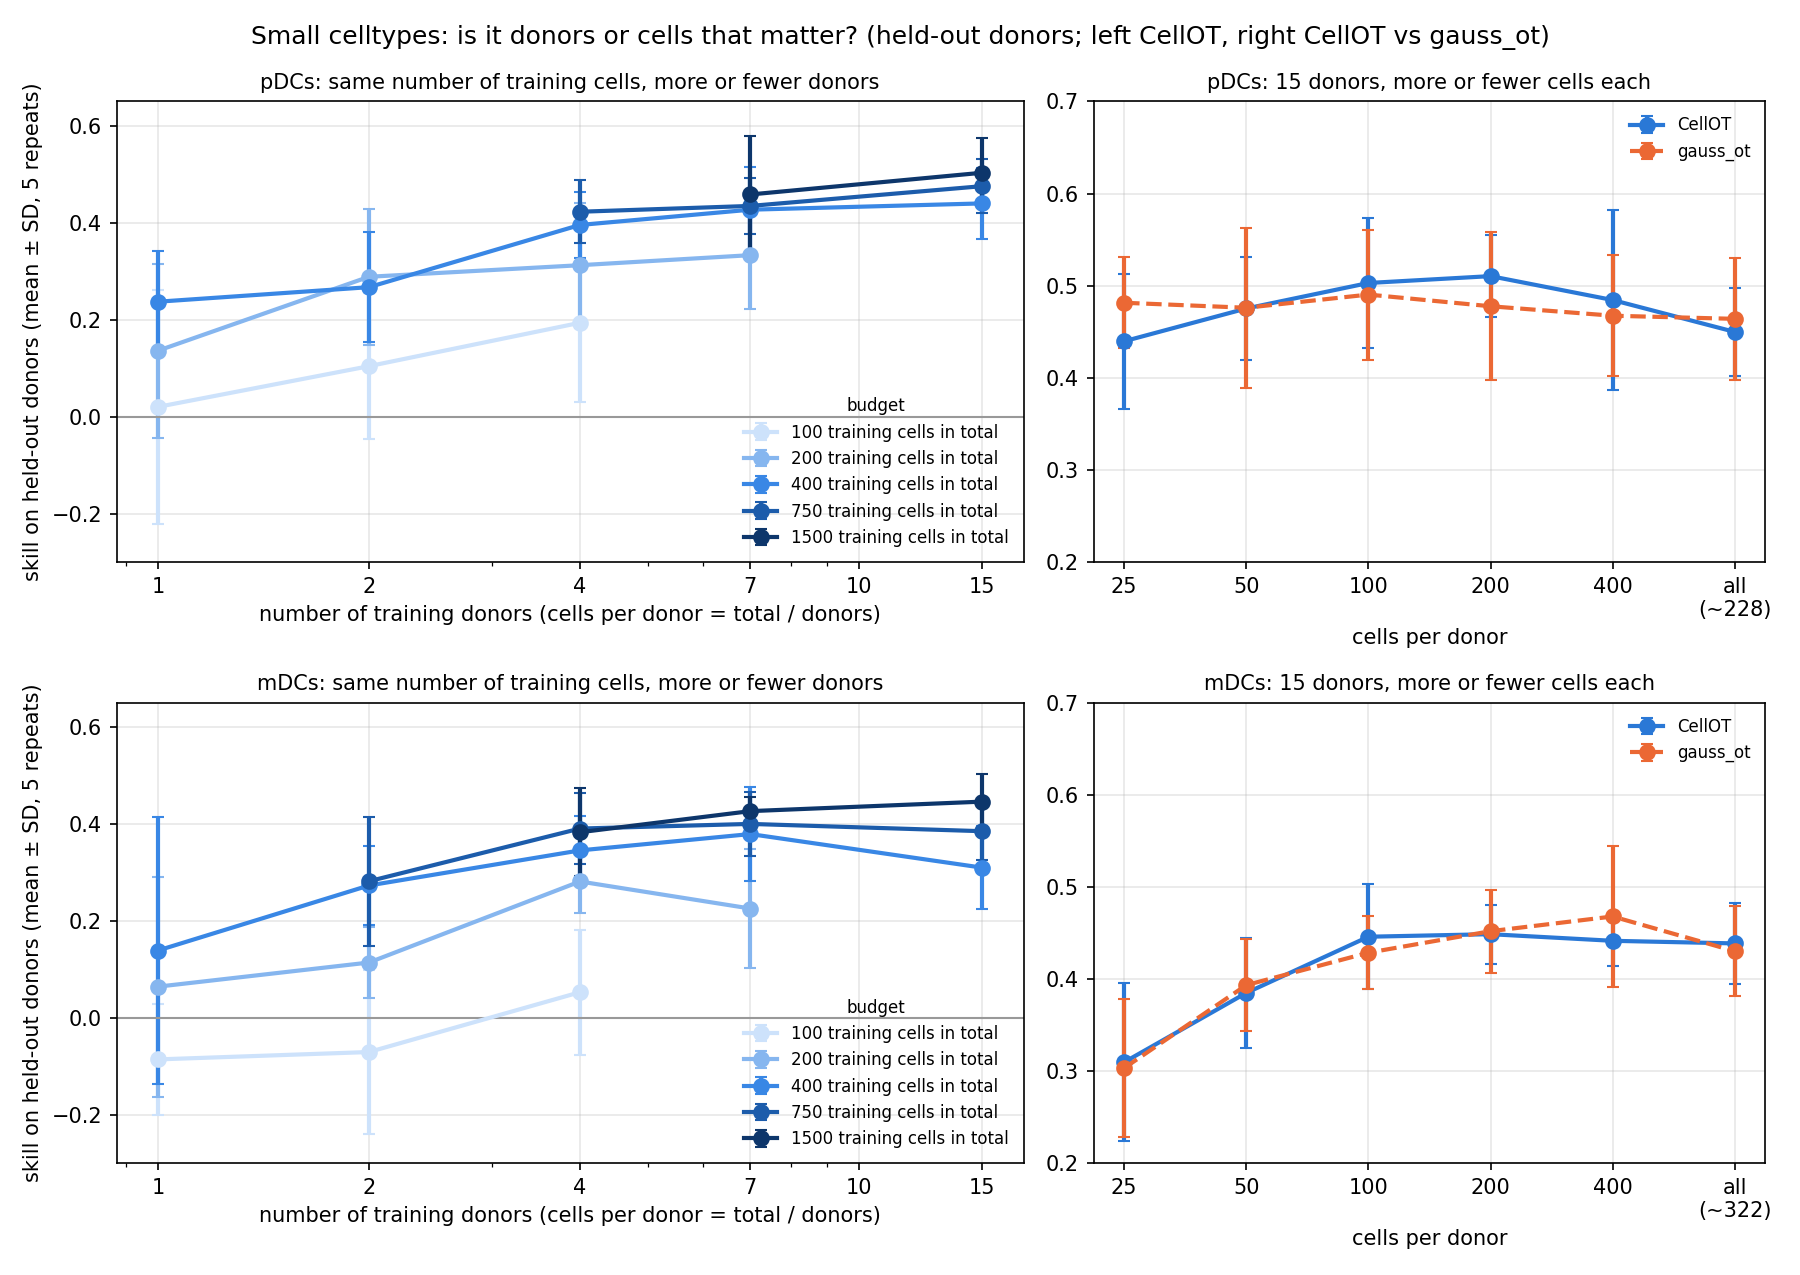

In [21]:
SB = D / "small_budget"; E = pd.read_csv(SB / "equal_budget.csv")
for ct in ["pDCs", "mDCs"]:
    t = E[(E.celltype == ct) & (E.method == "CellOT")]
    t = t.assign(v=[f"{s:.2f} ± {d:.2f}  ({int(k)}×{int(c)})" for s, d, k, c in zip(t.skill, t.sd, t.k, t.cap)])
    display(t.pivot_table(index="budget", columns="k", values="v", aggfunc="first").fillna("")
            .style.set_caption(f"{ct}, CellOT: skill at the same total budget (rows) with more donors (columns)"))
K = pd.read_csv(SB / "k15_by_cap.csv"); K = K[K.method.isin(["CellOT", "gauss_ot"])]
display(K.assign(v=[f"{s:.2f} ± {d:.2f}" for s, d in zip(K.skill, K.sd)])
        .pivot_table(index=["celltype", "method"], columns="cap", values="v", aggfunc="first")
        .rename(columns={0: "all"}).style.set_caption("15 donors: skill by cells per donor"))
Image(str(SB / "small_budget.png"))

**Reading.**
- **At the same total, more donors is better, until ~4–7 donors.** pDCs, 400 cells: 1 donor × 400 → 0.24,
  2 × 200 → 0.27, 4 × 100 → 0.40, 7 × 50 → 0.43, 15 × 25 → 0.44. mDCs, 400 cells: 0.14 → 0.27 → 0.35 → 0.38, then 0.31
  at 15 × 25. With 200 cells: pDCs 0.14 (1 donor) vs 0.31 (4 donors × 50).
- **Below ~50 cells per donor, cells start to matter too.** mDCs at 15 donors: 25 cells each 0.31, 50 → 0.39,
  100 → 0.45, then flat (200: 0.45, 400: 0.44, all: 0.44). So "15 × 25" loses to "7 × 50" in mDCs: splitting the budget
  too thin costs. pDCs tolerate 25 cells per donor better (0.44).
- **With 15 donors, taking all cells instead of 100 per donor changes nothing:** pDCs 0.45 (all, ~230 per donor) vs
  0.50 (100); mDCs 0.44 (all, ~320 per donor) vs 0.45 (100). The pDC differences between 50 and "all" (0.45–0.51) are
  within the repeat-to-repeat SD (0.05–0.10). "400" and "all" are nearly the same training set in pDCs (3,417 vs
  3,423 cells) and still differ by 0.03, which shows the noise level.
- **Practical rule for a small celltype:** ~100 cells per donor is enough; beyond that, spend effort on donors.
  gauss_ot shows the same pattern and is less hurt by very small budgets (pDCs 100 cells: 0.10–0.32 vs CellOT 0.02–0.19).

In [22]:
print(open(WORK / "STATUS.md").read())